
Normality (Shapiro–Wilk) on paired differences: W=0.990, p=0.99782

Paired t-test:
t(21) = 2.563, p = 0.018141

Paired difference (Session1 - Session2):
Median difference = 0.2293
IQR = [0.0212, 0.4753]
95% CI = [0.0410, 0.3945]
Cohen's dz = 0.546


/Users/garvert_UW/Library/Python/3.11/lib/python/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


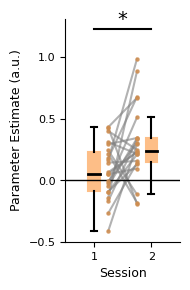

In [ ]:
# Figure 4D

# --- Imports ---
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import t, shapiro, ttest_rel
import math

# --- Config ---
CROSSMAP_KEY = '04_rel_dist_switch'   
CROSSMAP_LABEL = 'cross-map'          

main_dir = "../Data/ROI/Fig 4D 322_both_04_mPFC_2p5_mask"

# A function to parse the file name
def parse_file_name(file_name):
    # Extract participant ID and session based on your naming structure
    
    match = re.match(r"(\d{2})_(\d)_\d{3}_.*", file_name)
    match = re.match(r"(\d{2})_(\d)_.*", file_name)
    # match = re.match(r"(\d{2})(\d)(\d{3}).*", file_name)
    if match:
        
        participant_id = match.group(1)
        session = match.group(2)
        return participant_id, session
    return None, None

# --- Helper: build tidy data for just the cross-map condition ---
def _build_crossmap_long(data, remove_outliers):
    """
    From nested dict: data[session][condition][participant] -> value,
    return long df with columns: Participant, Session (str), Value (float).
    Outliers are removed separately within each session for the cross-map condition.
    """
    records = []
    # Ensure session order is consistent (e.g., '1' then '2')
    sessions = sorted(map(str, data.keys()), key=lambda s: int(s) if s.isdigit() else s)

    for sess in sessions:
        # Safeguard: tolerate int keys in data
        sess_key = int(sess) if sess.isdigit() and int(sess) in data else sess
        crossmap_dict = data.get(sess_key, {}).get(CROSSMAP_KEY, {})
        if not isinstance(crossmap_dict, dict):
            continue

        df = pd.DataFrame(list(crossmap_dict.items()), columns=['Participant', 'Value'])
        # Outlier removal per session
        df = remove_outliers(df)
        df['Session'] = str(sess)
        records.append(df[['Participant', 'Session', 'Value']])

    if not records:
        return pd.DataFrame(columns=['Participant', 'Session', 'Value'])

    long_df = pd.concat(records, ignore_index=True).dropna(subset=['Value'])
    return long_df

def remove_outliers(df):
    mean = df['Value'].mean()
    std = df['Value'].std()
    # Only keep data within the range [mean - 3*std, mean + 3*std]
    return df[(df['Value'] >= mean - 3 * std) & (df['Value'] <= mean + 3 * std)]

# Dictionary to store data: {session: {condition: {participant_id: value}}}
data = {}

# Loop through all the folders and files in the directory and subdirectories
for root, dirs, files in os.walk(main_dir):
    # Get the condition name (folder name)
    condition = os.path.basename(root)

    
    
    for file in files:
        if file.endswith(".txt"):
            file_path = os.path.join(root, file)

             # Extract participant ID and session
            participant_id, session = parse_file_name(file)


            if participant_id and session:
                # Read the number in the file
                try:
                    
                    with open(file_path, 'r') as f:
                        value = float(f.read().strip())


                    # Add data to the dictionary
                    if session not in data:
                        data[session] = {}
                    if condition not in data[session]:
                        data[session][condition] = {}
                    data[session][condition][participant_id] = value
                
                except ValueError:
                    continue
                except Exception as e:
                    print(f"Error processing file {file_path}: {e}")

# --- Build dataframes ---
melted_df = _build_crossmap_long(data, remove_outliers)

# Pivot to paired wide format (only participants with both sessions)
if melted_df.empty:
    raise ValueError("No data found for condition '04_rel_dist_switch' in any session.")

# Determine (sorted) session labels present, e.g., ['1','2']
present_sessions = sorted(melted_df['Session'].unique(), key=lambda s: int(s) if s.isdigit() else s)
if len(present_sessions) < 2:
    raise ValueError("Need two sessions to plot paired lines (found: %s)" % present_sessions)

s1, s2 = present_sessions[:2]  # use the first two sorted sessions (e.g., '1', '2')

wide = melted_df.pivot_table(index='Participant', columns='Session', values='Value', aggfunc='mean')
paired_df = wide.dropna(subset=[s1, s2]).rename(columns={s1: 'Session1', s2: 'Session2'}).reset_index(drop=False)

# Differences

# Extract paired values
x1 = paired_df['Session1'].to_numpy(float)
x2 = paired_df['Session2'].to_numpy(float)

diffs = x2 - x1

# ---- 1) Normality test ----
W, p_shapiro = shapiro(diffs)
print(f"\nNormality (Shapiro–Wilk) on paired differences: W={W:.3f}, p={p_shapiro:.5f}")

# Paired t-test
sd_diff = diffs.std(ddof=1)
mean_diff = diffs.mean()
dz = mean_diff / sd_diff
med_diff = np.median(diffs)
iqr_diff = np.percentile(diffs, [25, 75])

# 95% CI for mean difference
n = len(diffs)
dfree = n - 1
se = sd_diff / math.sqrt(n)
tcrit = t.ppf(0.975, dfree)
ci_low = mean_diff - tcrit * se
ci_high = mean_diff + tcrit * se
t_stat, p_value = ttest_rel(x2, x1)

print(f"\nPaired t-test:")
print(f"t({dfree}) = {t_stat:.3f}, p = {p_value:.6f}")

print("\nPaired difference (Session1 - Session2):")
print(f"Median difference = {med_diff:.4f}")
print(f"IQR = [{iqr_diff[0]:.4f}, {iqr_diff[1]:.4f}]")
print(f"95% CI = [{ci_low:.4f}, {ci_high:.4f}]")
print(f"Cohen's dz = {dz:.3f}")

# --- Plotting (target style) ---
plt.figure(figsize=(2, 3))

# Boxplot over sessions, only cross-map values
# Keep session order (s1 then s2) for consistent left->right plotting
plot_df = melted_df[melted_df['Session'].isin([s1, s2])].copy()
plot_df['Session'] = pd.Categorical(plot_df['Session'], categories=[s1, s2], ordered=True)

sns.boxplot(
    data=plot_df, x='Session', y='Value', width=0.2,
    boxprops=dict(facecolor='#FDBE87', edgecolor='#FDBE87'),
    medianprops=dict(color='black', linewidth=2),
    whiskerprops=dict(color='black'),
    capprops=dict(color='black'),
    showcaps=True, showfliers=False
)

# Scatter + connecting lines for paired subjects
# Compute x positions based on ticks (0 for s1, 1 for s2)
x_pos_map = {s1: 0, s2: 1}
session_offsets = {s1: 0.25, s2: -0.25}  # slight horizontal jitter so points don't sit on the box centers

ax = plt.gca()
for _, row in paired_df.iterrows():
    val1 = row['Session1']
    val2 = row['Session2']
    x1 = x_pos_map[s1] + session_offsets[s1]
    x2 = x_pos_map[s2] + session_offsets[s2]
    plt.plot([x1, x2], [val1, val2], color='gray', alpha=0.6, zorder=1)
    plt.scatter(x1, val1, color="#CE8D50", alpha=0.8, zorder=10, s=5)
    plt.scatter(x2, val2, color="#CE8D50", alpha=0.8, zorder=10, s=5)

# Significance bar (only if paired data exists)
if not np.isnan(p_value):
    y_max = float(plot_df['Value'].max())
    # place bar slightly above the top data point (also ensure it’s above 0 if all data ≤ 0)
    bar_y = max(y_max, 0) + (abs(y_max) + 1e-6) * 0.25
    if p_value < 0.05:
        plt.plot([0, 1], [bar_y, bar_y], color='black', linewidth=1.5)
        plt.text(0.5, bar_y, '*', ha='center', va='bottom', fontsize=14)

# Style
for spine in ax.spines.values():
    spine.set_color('black')

plt.xlabel("Session", fontsize=9)
plt.ylabel("Parameter Estimate (a.u.)", fontsize=9)
plt.xticks([0, 1], [s1, s2], fontsize=8)
plt.yticks(fontsize=8)
plt.tick_params(axis='both', which='both', bottom=True, top=False, left=True, right=False)
plt.grid(False)
plt.axhline(0, color="black", linewidth=1, zorder=0)
sns.despine()
plt.yticks([-0.5, 0, 0.5, 1])
plt.tight_layout()
plt.show()




Normality (Shapiro–Wilk) on paired differences: W=0.958, p=0.44219

Paired t-test:
t(21) = 2.379, p = 0.026900

Paired difference (Session1 - Session2):
Median difference = 0.1683
IQR = [-0.1322, 0.3453]
SE = 0.0708
95% CI = [0.0212, 0.3159]
Cohen's dz = 0.507


/Users/garvert_UW/Library/Python/3.11/lib/python/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


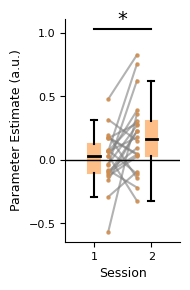

In [ ]:
# Figure 4E
# 
# # --- Imports ---
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_rel

# --- Config ---
CROSSMAP_KEY = '04_rel_dist_switch'   
CROSSMAP_LABEL = 'cross-map'          

main_dir = "../Data/ROI/Fig 4E AlexaFig2_thr3p1_both_mPFC"

# A function to parse the file name
def parse_file_name(file_name):
    # Extract participant ID and session based on your naming structure
    
    match = re.match(r"(\d{2})_(\d)_.*", file_name)
    if match:
        
        participant_id = match.group(1)
        session = match.group(2)
        return participant_id, session
    return None, None

# --- Helper: build tidy data for just the cross-map condition ---
def _build_crossmap_long(data, remove_outliers):
    """
    From nested dict: data[session][condition][participant] -> value,
    return long df with columns: Participant, Session (str), Value (float).
    Outliers are removed separately within each session for the cross-map condition.
    """
    records = []
    # Ensure session order is consistent (e.g., '1' then '2')
    sessions = sorted(map(str, data.keys()), key=lambda s: int(s) if s.isdigit() else s)

    for sess in sessions:
        # Safeguard: tolerate int keys in data
        sess_key = int(sess) if sess.isdigit() and int(sess) in data else sess
        crossmap_dict = data.get(sess_key, {}).get(CROSSMAP_KEY, {})
        if not isinstance(crossmap_dict, dict):
            continue

        df = pd.DataFrame(list(crossmap_dict.items()), columns=['Participant', 'Value'])
        # Outlier removal per session
        df = remove_outliers(df)
        df['Session'] = str(sess)
        records.append(df[['Participant', 'Session', 'Value']])

    if not records:
        return pd.DataFrame(columns=['Participant', 'Session', 'Value'])

    long_df = pd.concat(records, ignore_index=True).dropna(subset=['Value'])
    return long_df

def remove_outliers(df):
    mean = df['Value'].mean()
    std = df['Value'].std()
    # Only keep data within the range [mean - 3*std, mean + 3*std]
    return df[(df['Value'] >= mean - 3 * std) & (df['Value'] <= mean + 3 * std)]

# Dictionary to store data: {session: {condition: {participant_id: value}}}
data = {}

# Loop through all the folders and files in the directory and subdirectories
for root, dirs, files in os.walk(main_dir):
    # Get the condition name (folder name)
    condition = os.path.basename(root)

    
    
    for file in files:
        if file.endswith(".txt"):
            file_path = os.path.join(root, file)

             # Extract participant ID and session
            participant_id, session = parse_file_name(file)


            if participant_id and session:
                # Read the number in the file
                try:
                    
                    with open(file_path, 'r') as f:
                        value = float(f.read().strip())


                    # Add data to the dictionary
                    if session not in data:
                        data[session] = {}
                    if condition not in data[session]:
                        data[session][condition] = {}
                    data[session][condition][participant_id] = value
                
                except ValueError:
                    continue
                except Exception as e:
                    print(f"Error processing file {file_path}: {e}")

# --- Build dataframes ---
melted_df = _build_crossmap_long(data, remove_outliers)

# Pivot to paired wide format (only participants with both sessions)
if melted_df.empty:
    raise ValueError("No data found for condition '04_rel_dist_switch' in any session.")

# Determine (sorted) session labels present, e.g., ['1','2']
present_sessions = sorted(melted_df['Session'].unique(), key=lambda s: int(s) if s.isdigit() else s)
if len(present_sessions) < 2:
    raise ValueError("Need two sessions to plot paired lines (found: %s)" % present_sessions)

s1, s2 = present_sessions[:2]  # use the first two sorted sessions (e.g., '1', '2')

wide = melted_df.pivot_table(index='Participant', columns='Session', values='Value', aggfunc='mean')
paired_df = wide.dropna(subset=[s1, s2]).rename(columns={s1: 'Session1', s2: 'Session2'}).reset_index(drop=False)

# Extract paired values
x1 = paired_df['Session1'].to_numpy(float)
x2 = paired_df['Session2'].to_numpy(float)

diffs = x2 - x1

# ---- 1) Normality test ----
W, p_shapiro = shapiro(diffs)
print(f"\nNormality (Shapiro–Wilk) on paired differences: W={W:.3f}, p={p_shapiro:.5f}")

# Paired t-test
sd_diff = diffs.std(ddof=1)
mean_diff = diffs.mean()
dz = mean_diff / sd_diff
med_diff = np.median(diffs)
iqr_diff = np.percentile(diffs, [25, 75])

# 95% CI for mean difference
n = len(diffs)
dfree = n - 1
se = sd_diff / math.sqrt(n)
tcrit = t.ppf(0.975, dfree)
ci_low = mean_diff - tcrit * se
ci_high = mean_diff + tcrit * se
t_stat, p_value = ttest_rel(x2, x1)

print(f"\nPaired t-test:")
print(f"t({dfree}) = {t_stat:.3f}, p = {p_value:.6f}")


print("\nPaired difference (Session1 - Session2):")
print(f"Median difference = {med_diff:.4f}")
print(f"IQR = [{iqr_diff[0]:.4f}, {iqr_diff[1]:.4f}]")

print(f"SE = {se:.4f}")
print(f"95% CI = [{ci_low:.4f}, {ci_high:.4f}]")
print(f"Cohen's dz = {dz:.3f}")

# --- Plotting (target style) ---
plt.figure(figsize=(2, 3))

# Boxplot over sessions, only cross-map values
# Keep session order (s1 then s2) for consistent left->right plotting
plot_df = melted_df[melted_df['Session'].isin([s1, s2])].copy()
plot_df['Session'] = pd.Categorical(plot_df['Session'], categories=[s1, s2], ordered=True)

sns.boxplot(
    data=plot_df, x='Session', y='Value', width=0.2,
    boxprops=dict(facecolor='#FDBE87', edgecolor='#FDBE87'),
    medianprops=dict(color='black', linewidth=2),
    whiskerprops=dict(color='black'),
    capprops=dict(color='black'),
    showcaps=True, showfliers=False
)

# Scatter + connecting lines for paired subjects
# Compute x positions based on ticks (0 for s1, 1 for s2)
x_pos_map = {s1: 0, s2: 1}
session_offsets = {s1: 0.25, s2: -0.25}  # slight horizontal jitter so points don't sit on the box centers

ax = plt.gca()
for _, row in paired_df.iterrows():
    val1 = row['Session1']
    val2 = row['Session2']
    x1 = x_pos_map[s1] + session_offsets[s1]
    x2 = x_pos_map[s2] + session_offsets[s2]
    plt.plot([x1, x2], [val1, val2], color='gray', alpha=0.6, zorder=1)
    plt.scatter(x1, val1, color="#CE8D50", alpha=0.8, zorder=10, s=5)
    plt.scatter(x2, val2, color="#CE8D50", alpha=0.8, zorder=10, s=5)

# Significance bar (only if paired data exists)
if not np.isnan(p_value):
    y_max = float(plot_df['Value'].max())
    # place bar slightly above the top data point (also ensure it’s above 0 if all data ≤ 0)
    bar_y = max(y_max, 0) + (abs(y_max) + 1e-6) * 0.25
    if p_value < 0.05:
        plt.plot([0, 1], [bar_y, bar_y], color='black', linewidth=1.5)
        plt.text(0.5, bar_y, '*', ha='center', va='bottom', fontsize=14)

# Style
for spine in ax.spines.values():
    spine.set_color('black')

plt.xlabel("Session", fontsize=9)
plt.ylabel("Parameter Estimate (a.u.)", fontsize=9)
plt.xticks([0, 1], [s1, s2], fontsize=8)
plt.yticks(fontsize=8)
plt.tick_params(axis='both', which='both', bottom=True, top=False, left=True, right=False)
plt.grid(False)
plt.axhline(0, color="black", linewidth=1, zorder=0)
sns.despine()
plt.yticks([-0.5, 0, 0.5, 1])
plt.tight_layout()
plt.show()




Normality (Shapiro–Wilk) on paired differences: W=0.940, p=0.20139

Paired t-test:
t(21) = 2.871, p = 0.009142

Paired difference (Session2 - Session1):
Median difference = 0.022395
IQR = [-0.008356, 0.086625]
SE = 0.011733
95% CI = [0.009287, 0.058088]
Cohen's dz = 0.612


/Users/garvert_UW/Library/Python/3.11/lib/python/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


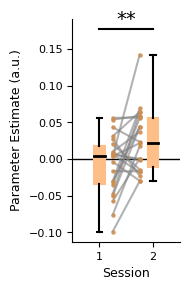

In [ ]:
# Figure 4H
# 
# # --- Imports ---
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_rel, shapiro, t

# --- Config: path to CSV ---
csv_path = '/Users/garvert_UW/University of Wuerzburg Dropbox/Mona Garvert/DropboxFiles/Privat/Projects/ManyMaps/Paper/Second round/Submission second round/ManyMaps/Data/ROI/Fig 4H/tau_322_diff_04_mPFCsmaller_2p5_distRel_diffMaps.csv'

# --- Load CSV ---
wide = pd.read_csv(csv_path, header=None)

if wide.shape[1] < 2:
    raise ValueError(f"Expected at least 2 columns (Session1, Session2), got {wide.shape[1]}.")

wide = wide.iloc[:, :2].copy()
wide.columns = ["Session1", "Session2"]

# Drop rows with missing values (if any)
wide = wide.dropna(subset=["Session1", "Session2"]).reset_index(drop=True)

# --- Stats (paired) ---
x1 = wide["Session1"].to_numpy(float)
x2 = wide["Session2"].to_numpy(float)
diffs = x2 - x1

W, p_shapiro = shapiro(diffs)
print(f"\nNormality (Shapiro–Wilk) on paired differences: W={W:.3f}, p={p_shapiro:.5f}")

t_stat, p_value = ttest_rel(x2, x1)

sd_diff = diffs.std(ddof=1)
mean_diff = diffs.mean()
dz = mean_diff / sd_diff if sd_diff != 0 else np.nan

n = len(diffs)
dfree = n - 1
se = sd_diff / math.sqrt(n) if n > 0 else np.nan
tcrit = t.ppf(0.975, dfree) if n > 1 else np.nan
ci_low = mean_diff - tcrit * se if n > 1 else np.nan
ci_high = mean_diff + tcrit * se if n > 1 else np.nan

med_diff = np.median(diffs)
iqr25, iqr75 = np.percentile(diffs, [25, 75])

print(f"\nPaired t-test:")
print(f"t({dfree}) = {t_stat:.3f}, p = {p_value:.6f}")

print("\nPaired difference (Session2 - Session1):")
print(f"Median difference = {med_diff:.6f}")
print(f"IQR = [{iqr25:.6f}, {iqr75:.6f}]")
print(f"SE = {se:.6f}")
print(f"95% CI = [{ci_low:.6f}, {ci_high:.6f}]")
print(f"Cohen's dz = {dz:.3f}")

# --- Build long df for plotting (like your original code) ---
melted_df = wide.reset_index(names="Participant").melt(
    id_vars="Participant",
    value_vars=["Session1", "Session2"],
    var_name="Session",
    value_name="Value"
)

# --- Plotting (same style idea as your original) ---
plt.figure(figsize=(2, 3))

# Boxplot
plot_df = melted_df.copy()
plot_df["Session"] = pd.Categorical(plot_df["Session"], categories=["Session1", "Session2"], ordered=True)

sns.boxplot(
    data=plot_df, x="Session", y="Value", width=0.2,
    boxprops=dict(facecolor="#FDBE87", edgecolor="#FDBE87"),
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black"),
    showcaps=True, showfliers=False
)

# Paired lines + points
ax = plt.gca()
x_pos_map = {"Session1": 0, "Session2": 1}
session_offsets = {"Session1": 0.25, "Session2": -0.25}

for i, row in wide.reset_index().iterrows():
    val1 = row["Session1"]
    val2 = row["Session2"]
    x_a = x_pos_map["Session1"] + session_offsets["Session1"]
    x_b = x_pos_map["Session2"] + session_offsets["Session2"]
    plt.plot([x_a, x_b], [val1, val2], color="gray", alpha=0.6, zorder=1)
    plt.scatter(x_a, val1, color="#CE8D50", alpha=0.8, zorder=10, s=5)
    plt.scatter(x_b, val2, color="#CE8D50", alpha=0.8, zorder=10, s=5)

# Significance bar
if not np.isnan(p_value):
    y_max = float(plot_df["Value"].max())
    bar_y = max(y_max, 0) + (abs(y_max) + 1e-6) * 0.25
    if p_value < 0.01:
        plt.plot([0, 1], [bar_y, bar_y], color="black", linewidth=1.5)
        plt.text(0.5, bar_y, "**", ha="center", va="bottom", fontsize=14)

# Style
for spine in ax.spines.values():
    spine.set_color("black")

plt.xlabel("Session", fontsize=9)
plt.ylabel("Parameter Estimate (a.u.)", fontsize=9)
plt.xticks([0, 1], ["1", "2"], fontsize=8)  # show as "1" and "2" if you prefer
plt.yticks(fontsize=8)
plt.tick_params(axis="both", which="both", bottom=True, top=False, left=True, right=False)
plt.grid(False)
plt.axhline(0, color="black", linewidth=1, zorder=0)
sns.despine()
plt.tight_layout()
plt.savefig("/Users/garvert_UW/University of Wuerzburg Dropbox/Mona Garvert/DropboxFiles/Privat/Projects/ManyMaps/Paper/Second round/Submission second round/ManyMaps/Data/ROI/Fig 4H/tau_322_diff_04_mPFCsmaller_2p5_distRel_diffMaps.pdf", bbox_inches="tight")
plt.show()